# 03 · Rain prediction — probability first, amount second

**Task:** estimate (a) the probability that the next day is wet, and (b) how much rain
falls if it is.

**Why two models instead of one:** in this record **47.9% of region-days are exactly
0.0 mm**. A single squared-error regression on millimetres is dominated by getting the
zeros right and says almost nothing about the tail. The standard treatment in rainfall
modelling is a two-part (hurdle) model: a classifier for occurrence, then a positive
regression for amount. It also gives the user two honest numbers — "60% chance of rain"
and "if it rains, about 12 mm" — instead of one misleading average.

**Evidence base:** two-part rainfall models are standard in agro-meteorology (Wilks,
*Statistical Methods in the Atmospheric Sciences*); probability forecasts are scored
with Brier score and log loss rather than accuracy, because accuracy is trivially high
when 70% of days are dry.

Outputs: `rain_model_scores.csv`, reliability curve, amount model comparison.

In [1]:
# --- shared setup -----------------------------------------------------------
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

DATA = Path(os.environ.get("BH6_DATA", r"C:\Users\muhai\Desktop\BIG hero 6\Data"))
MR = DATA / "model_ready"
OUT = Path(os.environ.get("BH6_OUT", str(Path.cwd() / "outputs")))
OUT.mkdir(parents=True, exist_ok=True)

regions = ["Northwest_Rajshahi", "North_Rangpur", "Central_Dhaka", "Northeast_Sylhet",
           "Southwest_Khulna", "South_Barishal", "Southeast_Chattogram"]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3de"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 10, "axes.titlecolor": INK, "axes.spines.top": False,
    "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.8,
})
SEQ = LinearSegmentedColormap.from_list("brand_blue", ["#eaf2fc", "#9cc3ef", "#2a78d6", "#12365f"])

def pretty(region):
    return region.replace("_", " ")

def load_daily():
    df = pd.read_csv(MR / "daily_panel.csv", parse_dates=["date"])
    return df.sort_values(["region", "date"]).reset_index(drop=True)

def load_monthly():
    df = pd.read_csv(MR / "monthly_panel.csv", parse_dates=["date"])
    return df.sort_values(["region", "date"]).reset_index(drop=True)

def split_by_date(dates, train_end="2024-12-31", valid_end="2025-12-31"):
    d = pd.to_datetime(dates)
    return (d <= train_end), (d > train_end) & (d <= valid_end), d > valid_end

def metrics(y_true, y_pred):
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = np.isfinite(y_true) & np.isfinite(y_pred)
    if ok.sum() < 5:
        return {"n": int(ok.sum())}
    return {"n": int(ok.sum()),
            "MAE": round(float(mean_absolute_error(y_true[ok], y_pred[ok])), 3),
            "RMSE": round(float(np.sqrt(mean_squared_error(y_true[ok], y_pred[ok]))), 3),
            "R2": round(float(r2_score(y_true[ok], y_pred[ok])), 3)}

print(f"pandas {pd.__version__} | data: {DATA}")


pandas 3.1.1 | data: C:\Users\muhai\Desktop\BIG hero 6\Data


## 1. Build the occurrence and amount targets

A day counts as wet at ≥ 0.1 mm (the conventional tipping-bucket threshold). The
distinction matters: 0.02 mm is dew, not rain.

In [2]:
daily = load_daily()
g = daily.groupby("region", group_keys=False)
daily["rain_next"] = g["gpm_rain_mm"].shift(-1)
daily["wet_next"] = (daily["rain_next"] >= 0.1).astype(float)
daily.loc[daily["rain_next"].isna(), "wet_next"] = np.nan

print("days with a next-day observation:", int(daily.rain_next.notna().sum()))
print("share of wet next-days:", round(float(daily.wet_next.mean()), 3))
print("\nby month (share of days wet):")
print(daily.groupby(daily.date.dt.month)["wet_next"].mean().round(2).to_string())

days with a next-day observation: 12306
share of wet next-days: 0.483

by month (share of days wet):
date
1     0.07
2     0.11
3     0.28
4     0.36
5     0.64
6     0.82
7     0.92
8     0.93
9     0.86
10    0.45
11    0.09
12    0.07


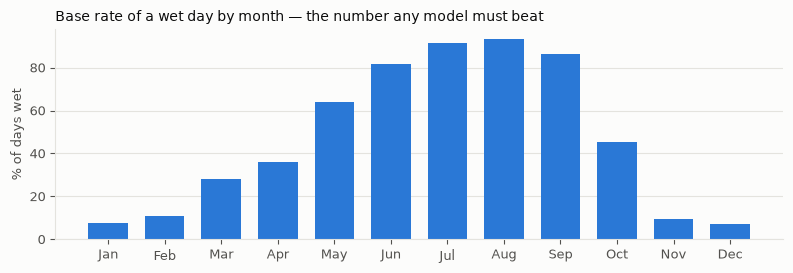

In [3]:
fig, ax = plt.subplots(figsize=(8, 2.8))
monthly_rate = daily.groupby(daily.date.dt.month)["wet_next"].mean()
ax.bar(monthly_rate.index, monthly_rate.values * 100, color=BLUE, width=0.7)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(months)
ax.set_ylabel("% of days wet"); ax.grid(axis="y"); ax.set_axisbelow(True)
ax.set_title("Base rate of a wet day by month — the number any model must beat", loc="left")
fig.tight_layout(); plt.show()

## 2. Features

Rainfall history is the strongest available predictor: how many of the last 7 days were
wet, and how much fell over 3, 7 and 30 days. Temperature range and humidity carry the
atmospheric state.

In [4]:
def rain_features(df):
    X = df[["t2m_c", "tmax_c", "tmin_c", "diurnal_range_c", "rh_pct", "wind_ms",
            "solar_mj_m2", "pressure_kpa", "vpd_kpa", "power_rain_mm", "gpm_rain_mm",
            "power_rain_sum_3d", "power_rain_sum_7d", "power_rain_sum_30d",
            "gpm_rain_sum_7d", "dry_spell_days", "doy_sin", "doy_cos", "month"]].copy()
    past = df.groupby("region", group_keys=False)
    X["rain_days_7d"] = past["gpm_rain_mm"].apply(lambda s: (s >= 0.1).rolling(7, min_periods=3).sum())
    X["rain_days_14d"] = past["gpm_rain_mm"].apply(lambda s: (s >= 0.1).rolling(14, min_periods=5).sum())
    X["rain_lag1"] = past["gpm_rain_mm"].shift(1)
    return pd.concat([X, pd.get_dummies(df["region"], prefix="region", dtype=float)], axis=1)

X = rain_features(daily)
train, valid, test = split_by_date(daily["date"])
print("features:", X.shape[1])

features: 29


## 3. Stage 1 — probability of a wet day

Logistic regression gives a calibrated probability directly; gradient boosting may
rank better but needs calibration. Both are compared on **Brier score** (lower is
better), **log loss** and **AUC**, against the seasonal base rate.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

usable = daily["wet_next"].notna()
tr, te = train & usable, test & usable
Xtr, ytr = X[tr], daily.loc[tr, "wet_next"]
Xte, yte = X[te], daily.loc[te, "wet_next"]

base_rate = ytr.groupby(daily.loc[tr, "date"].dt.month).mean()
base_pred = np.clip(daily.loc[te, "date"].dt.month.map(base_rate).to_numpy(), 1e-3, 1 - 1e-3)

logit = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      LogisticRegression(max_iter=1000, class_weight="balanced"))
logit.fit(Xtr, ytr)
p_logit = logit.predict_proba(Xte)[:, 1]

gbc = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, min_samples_leaf=30, random_state=0)
gbc.fit(Xtr, ytr)
p_gbc = gbc.predict_proba(Xte)[:, 1]

occ = pd.DataFrame([
    {"model": "seasonal base rate", "AUC": round(roc_auc_score(yte, base_pred), 3),
     "Brier": round(brier_score_loss(yte, base_pred), 4), "log loss": round(log_loss(yte, base_pred), 4)},
    {"model": "logistic regression", "AUC": round(roc_auc_score(yte, p_logit), 3),
     "Brier": round(brier_score_loss(yte, p_logit), 4), "log loss": round(log_loss(yte, p_logit), 4)},
    {"model": "gradient boosting", "AUC": round(roc_auc_score(yte, p_gbc), 3),
     "Brier": round(brier_score_loss(yte, p_gbc), 4), "log loss": round(log_loss(yte, p_gbc), 4)},
])
occ.to_csv(OUT / "rain_occurrence_scores.csv", index=False)
occ

,model,AUC,Brier,log loss
0,seasonal base rate,0.864,0.1504,0.4623
1,logistic regression,0.900,0.1269,0.3961
2,gradient boosting,0.904,0.1256,0.3890


## 4. Is the probability honest?

A forecast that says 70% should be right about 70% of the time. The reliability curve
plots predicted probability against observed frequency; the diagonal is perfect
calibration.

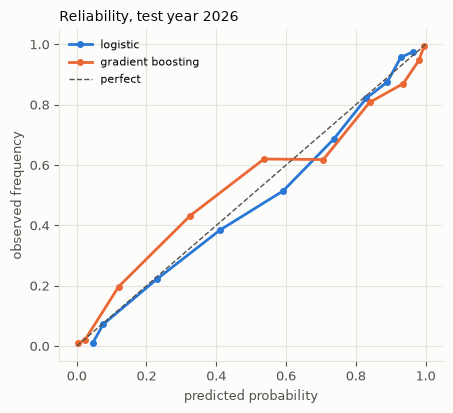

In [6]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(4.6, 4.2))
for name, p, color in [("logistic", p_logit, BLUE), ("gradient boosting", p_gbc, ORANGE)]:
    frac, mean_pred = calibration_curve(yte, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", markersize=4, linewidth=2, color=color, label=name)
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--", label="perfect")
ax.set_xlabel("predicted probability"); ax.set_ylabel("observed frequency")
ax.set_title("Reliability, test year 2026", loc="left")
ax.legend(frameon=False, fontsize=8); ax.grid(True); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()

## 5. Stage 2 — how much, given that it rains

Fitted only on wet days, with a Gamma loss (rainfall amounts are positive and
right-skewed — a squared-error fit would mostly chase the rare extremes).

In [7]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

wet_tr = tr & (daily["rain_next"] >= 0.1)
wet_te = te & (daily["rain_next"] >= 0.1)
Xw, yw = X[wet_tr], daily.loc[wet_tr, "rain_next"]
Xwt, ywt = X[wet_te], daily.loc[wet_te, "rain_next"]

amount_sq = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.06,
                                          min_samples_leaf=25, random_state=0)
amount_sq.fit(Xw, yw)
p_sq = np.clip(amount_sq.predict(Xwt), 0, None)

try:
    amount_gamma = HistGradientBoostingRegressor(loss="gamma", max_iter=300,
                                                 learning_rate=0.06, min_samples_leaf=25, random_state=0)
    amount_gamma.fit(Xw, yw)
    p_gamma = np.clip(amount_gamma.predict(Xwt), 0, None)
    have_gamma = True
except Exception as exc:
    have_gamma = False
    print("gamma loss unavailable:", exc)

rows = [{"model": "climatology (mean wet-day amount)", "MAE mm": round(mean_absolute_error(ywt, np.full(len(ywt), yw.mean())), 2)},
        {"model": "gradient boosting, squared error", "MAE mm": round(mean_absolute_error(ywt, p_sq), 2)}]
if have_gamma:
    rows.append({"model": "gradient boosting, gamma loss", "MAE mm": round(mean_absolute_error(ywt, p_gamma), 2)})
amounts = pd.DataFrame(rows)
amounts.to_csv(OUT / "rain_amount_scores.csv", index=False)
amounts

,model,MAE mm
0,climatology (mean wet-day amount),11.27
1,"gradient boosting, squared error",10.85
2,"gradient boosting, gamma loss",8.23


## 6. Putting the two stages together

The expected rainfall is P(wet) × E[amount | wet]. That is the number to show a user —
and it should be shown with the two components, not instead of them.

In [8]:
amount_all = np.clip((amount_gamma if have_gamma else amount_sq).predict(Xte), 0, None)
expected = p_logit * amount_all
final = pd.DataFrame({
    "date": daily.loc[te, "date"].to_numpy(),
    "region": daily.loc[te, "region"].to_numpy(),
    "observed_mm": yte, "p_wet": np.round(p_logit, 3),
    "expected_mm": np.round(expected, 2),
})
final.to_csv(OUT / "rain_next_day_forecasts.csv", index=False)
print("saved", len(final), "forecasts")
print("\ncalibration check: days with p_wet > 0.7 were wet",
      f"{(yte[final.p_wet > 0.7].mean()*100):.0f}% of the time (n={(final.p_wet>0.7).sum()})")
final.head(8)

saved 2079 forecasts

calibration check: days with p_wet > 0.7 were wet 87% of the time (n=996)


,date,region,observed_mm,p_wet,expected_mm
1461,2026-01-01,Central_Dhaka,0.0,0.055,0.01
1462,2026-01-02,Central_Dhaka,0.0,0.081,0.01
1463,2026-01-03,Central_Dhaka,0.0,0.077,0.01
1464,2026-01-04,Central_Dhaka,0.0,0.057,0.01
1465,2026-01-05,Central_Dhaka,0.0,0.072,0.02
1466,2026-01-06,Central_Dhaka,0.0,0.046,0.01
1467,2026-01-07,Central_Dhaka,0.0,0.037,0.01
1468,2026-01-08,Central_Dhaka,0.0,0.038,0.01


## 7. Limits — read before shipping

- **This is not a weather model.** It learns the local relationship between today's
  state and tomorrow's rain at a reanalysis grid cell. It cannot see a cyclone forming.
- **The dry-season signal is weak.** GPM reports near-zero rain in Nov–Feb while POWER
  reports tens of millimetres; the two disagree most exactly when both are small. Do not
  let a model learn a confident "0%" from that.
- **GPM Final Run lags ~3.5 months.** In production you would feed the Late Run and
  accept lower accuracy; record which run each forecast used.
- **Class balance shifts by month** (about 50% of days wet in July, ~5% in January).
  Aggregate metrics hide this — always report by season.